# Toronto_3D Quantization Deep Dive

A practical exploration of baseline inference and ONNX Runtime post-training quantization (PTQ) for the Toronto_3D PointNet model. The notebook compares accuracy, latency, throughput, file size, and the details encoded in QDQ models.

## Before you start

1. Place Toronto_3D PLY files under `data/Toronto_3D/`.
2. Train the nine-class Toronto model and export it:
   - `python -m src.train_toronto --data-dir data/Toronto_3D --train-scans L001.ply L002.ply L003.ply --val-scans L004.ply`
   - `python -m src.export_toronto_onnx --checkpoint outputs/checkpoints/pointnet_toronto.pt --parity-scan data/Toronto_3D/L004.ply`
3. Generate PTQ variants with calibration scans that are not used as held-out evaluation scans:
   - `python -m src.quantize_toronto --calib-scans L001.ply L002.ply`

The steps above can take time; this notebook does not launch training or quantization automatically. Run cells top-to-bottom after those artifacts are ready.

| Section | What you will investigate |
| --- | --- |
| 1. Load model and evaluation data | Check checkpoint metadata and build reproducible held-out tiles |
| 2. Baseline inference | Collect PyTorch and FP32 ONNX predictions |
| 3. Baseline performance | Measure mIoU, latency, throughput, and model size |
| 4–5. Prepare, calibrate, and apply PTQ | Calibrate six static QDQ variants with Toronto tiles |
| 6–7. Quantized inference and comparison | Compare outputs, accuracy, and runtime trade-offs |
| 8. Quantization details | Inspect QDQ nodes, scales, zero-points, and weight granularity |

In [7]:
import os
import sys
import time
from pathlib import Path
from collections import Counter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import torch

from src.model import load_checkpoint
from src.toronto_data import (
    NUM_TORONTO_CLASSES, TORONTO_CLASS_NAMES, Toronto3DTiles,
    load_toronto_scan_for_inference,
)
from src.quantize_toronto import TorontoCalibrationReader

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

DATA_DIR = Path("data/Toronto_3D")
CHECKPOINT = Path("outputs/checkpoints/pointnet_toronto.pt")
ONNX_DIR = Path("outputs/toronto_onnx")
FP32_ONNX = ONNX_DIR / "pointnet_toronto_fp32.onnx"
EVAL_SCANS = [DATA_DIR / "L004.ply"]  # held out from default training/calibration scans
CACHE_DIR = Path("outputs/toronto_cache")

assert CHECKPOINT.is_file(), "Train first using the command in the introduction."
assert all(path.is_file() for path in EVAL_SCANS), "Check DATA_DIR and EVAL_SCANS."

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model, checkpoint = load_checkpoint(str(CHECKPOINT), device=device)
N = int(checkpoint["n_points"])
TILE_SIZE = float(checkpoint.get("tile_size", 20.0))
COORD_SCALE = float(checkpoint.get("coord_scale", 25.0))
CLASS_NAMES = checkpoint.get("class_names", TORONTO_CLASS_NAMES)

# Evaluation tiles follow the same fixed-count feature and label preprocessing as training.
eval_ds = Toronto3DTiles(
    EVAL_SCANS, n_points=N, tile_size=TILE_SIZE, min_points=2048,
    coord_scale=COORD_SCALE, augment=False, cache_dir=CACHE_DIR, seed=20,
)
print(f"device={device}; epoch={checkpoint.get('epoch')}; n_points={N}; tiles={len(eval_ds)}")
print("validation metrics stored in checkpoint:", checkpoint.get("val", {}))

device=mps; epoch=21; n_points=2048; tiles=78
validation metrics stored in checkpoint: {'mIoU': 0.27220958467352196, 'OA': 0.6302333733974359, 'IoU_Unclassified': 0.014740505681236565, 'IoU_Ground': 0.7543040170826104, 'IoU_Road_markings': 0.27571825764596847, 'IoU_Natural': 0.5145803740883536, 'IoU_Building': 0.32275048368168985, 'IoU_Utility_line': 0.14502657555049356, 'IoU_Pole': 0.189878892733564, 'IoU_Car': 0.17505133470225873, 'IoU_Fence': 0.05783582089552239}


## 1. Load the model and evaluation data

Toronto tiles contain four channels: centered/scaled $x,y,z$ coordinates and intensity in $[0,1]$. The Z origin is the median source-point height within a tile; importantly, it does not depend on semantic labels, so deployment preprocessing can reproduce it. The checkpoint fixes the point count and carries the nine-class head and class names.

In [8]:
def confusion_from_predictions(predictions, targets, n_classes=NUM_TORONTO_CLASSES):
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    encoded = targets.reshape(-1) * n_classes + predictions.reshape(-1)
    cm += np.bincount(encoded, minlength=n_classes**2).reshape(n_classes, n_classes)
    return cm


def summarize_confusion(cm):
    tp = np.diag(cm).astype(np.float64)
    union = cm.sum(0) + cm.sum(1) - tp
    iou = np.divide(tp, union, out=np.full(NUM_TORONTO_CLASSES, np.nan), where=union > 0)
    return {"OA": float(tp.sum() / max(cm.sum(), 1)),
            "mIoU": float(np.nanmean(iou)), "IoU": iou}


def collect_torch_predictions(model, dataset, device, batch_size=8):
    model.eval()
    preds, targets, elapsed = [], [], []
    with torch.inference_mode():
        for start in range(0, len(dataset), batch_size):
            batch = [dataset[i] for i in range(start, min(start + batch_size, len(dataset)))]
            x = torch.stack([item[0] for item in batch]).to(device)
            y = torch.stack([item[1] for item in batch]).numpy()
            t0 = time.perf_counter()
            logits = model(x)
            if device.type == "mps":
                torch.mps.synchronize()
            elapsed.append(time.perf_counter() - t0)
            preds.append(logits.argmax(1).cpu().numpy())
            targets.append(y)
    return np.concatenate(preds), np.concatenate(targets), np.asarray(elapsed)


def collect_onnx_predictions(session, dataset):
    # Toronto ONNX export is static batch-1; match that input shape for every call.
    preds, targets, elapsed = [], [], []
    for index in range(len(dataset)):
        x, y = dataset[index]
        x = x.numpy()[None]
        t0 = time.perf_counter()
        logits = session.run(None, {"points": x})[0]
        elapsed.append(time.perf_counter() - t0)
        preds.append(logits.argmax(1)[0])
        targets.append(y.numpy())
    return np.stack(preds), np.stack(targets), np.asarray(elapsed)


def benchmark_onnx(session, sample, warmup=10, iterations=50):
    x = sample[None].astype(np.float32, copy=False)
    for _ in range(warmup):
        session.run(None, {"points": x})
    times = []
    for _ in range(iterations):
        t0 = time.perf_counter()
        session.run(None, {"points": x})
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times)), float(np.percentile(times, 99))

print("evaluation helpers ready")

evaluation helpers ready


## 2. Run baseline inference

The baseline is the trained PyTorch model. `eval()` disables training-only behavior such as dropout, and `inference_mode()` avoids autograd bookkeeping. Predictions and reference labels are retained to make later comparisons use precisely the same evaluation tiles.

In [9]:
baseline_pred, eval_targets, torch_batch_seconds = collect_torch_predictions(model, eval_ds, device)
baseline_cm = confusion_from_predictions(baseline_pred, eval_targets)
baseline_metrics = summarize_confusion(baseline_cm)
print(f"PyTorch baseline: OA={baseline_metrics['OA']:.4f}, mIoU={baseline_metrics['mIoU']:.4f}")
print("tiles evaluated:", len(eval_ds), "| prediction shape:", baseline_pred.shape)

PyTorch baseline: OA=0.6302, mIoU=0.2722
tiles evaluated: 78 | prediction shape: (78, 2048)


## 3. Measure baseline performance

Accuracy is computed over all labeled points in the fixed evaluation tiles. Throughput below is measured in tiles/second for batched evaluation; p50 and p99 are batch-1 ONNX CPU latency after warm-up. Model size is the serialized artifact size, not peak runtime memory.

In [10]:
baseline_row = {
    "model": "PyTorch fp32",
    "OA": baseline_metrics["OA"],
    "mIoU": baseline_metrics["mIoU"],
    "tiles_per_sec": len(eval_ds) / max(torch_batch_seconds.sum(), 1e-12),
    "size_kb": CHECKPOINT.stat().st_size / 1024,
}

if FP32_ONNX.is_file():
    fp32_session = ort.InferenceSession(str(FP32_ONNX), providers=["CPUExecutionProvider"])
    fp32_pred, onnx_targets, fp32_batch_seconds = collect_onnx_predictions(fp32_session, eval_ds)
    np.testing.assert_array_equal(eval_targets, onnx_targets)
    fp32_metrics = summarize_confusion(confusion_from_predictions(fp32_pred, eval_targets))
    fp32_p50, fp32_p99 = benchmark_onnx(fp32_session, eval_ds[0][0].numpy())
    fp32_row = {
        "model": "ONNX fp32", "OA": fp32_metrics["OA"], "mIoU": fp32_metrics["mIoU"],
        "tiles_per_sec": len(eval_ds) / max(fp32_batch_seconds.sum(), 1e-12),
        "p50_ms": fp32_p50, "p99_ms": fp32_p99, "size_kb": FP32_ONNX.stat().st_size / 1024,
    }
    print("FP32 ONNX: OA={OA:.4f}, mIoU={mIoU:.4f}, p50={p50_ms:.2f} ms, p99={p99_ms:.2f} ms".format(**fp32_row))
else:
    fp32_session = None
    fp32_row = None
    print("FP32 ONNX export not found; run src.export_toronto_onnx before PTQ comparison.")

print("PyTorch checkpoint size: {:.1f} KB".format(baseline_row["size_kb"]))

FP32 ONNX: OA=0.6302, mIoU=0.2722, p50=1.26 ms, p99=1.47 ms
PyTorch checkpoint size: 657.0 KB


## 4. Prepare the model for PTQ

This project uses ONNX Runtime static PTQ rather than PyTorch eager-mode quantization. The trained model is exported and preprocessed to ONNX, then the quantizer inserts Q/DQ pairs. We use per-channel int8 weights and uint8 activations as the baseline deployment recipe. Calibration must follow the same label-free XYZ/intensity preprocessing and point count as inference.

In [11]:
from src.quantize import variant_configs

if FP32_ONNX.is_file():
    prep_path = ONNX_DIR / "pointnet_toronto_fp32_prep.onnx"
    if not prep_path.is_file():
        from onnxruntime.quantization.shape_inference import quant_pre_process
        ONNX_DIR.mkdir(parents=True, exist_ok=True)
        quant_pre_process(str(FP32_ONNX), str(prep_path), skip_symbolic_shape=True)
    configs = variant_configs(prep_path)
    print("PTQ variants:", ", ".join(configs))
    print("prepared graph:", prep_path, "| bytes:", prep_path.stat().st_size)
else:
    prep_path = None
    configs = {}
    print("Export FP32 ONNX first; no model was found at", FP32_ONNX)

# Inspect the Toronto calibration reader without running quantization.
calibration_scans = [DATA_DIR / "L001.ply", DATA_DIR / "L002.ply"]
existing_calibration_scans = [path for path in calibration_scans if path.is_file()]
if existing_calibration_scans:
    calibration_reader = TorontoCalibrationReader(
        existing_calibration_scans, N, TILE_SIZE, COORD_SCALE, max_tiles=16,
    )
    calibration_reader.rewind()
    first_calibration_batch = calibration_reader.get_next()["points"]
    print("calibration sample shape:", first_calibration_batch.shape,
          "all finite:", np.isfinite(first_calibration_batch).all())
else:
    calibration_reader = None
    print("Add calibration PLYs to", DATA_DIR, "or run the PTQ CLI.")

PTQ variants: w8a8_pertensor, w8a8_perchannel, w8a8_percentile, w8a8_entropy, w8a8_head_fp32, w8a16
prepared graph: outputs/toronto_onnx/pointnet_toronto_fp32_prep.onnx | bytes: 675670
calibration sample shape: (1, 4, 2048) all finite: True


## 5. Calibrate and apply PTQ

Calibration estimates activation ranges from representative inputs; it does not use evaluation labels. The command-line workflow can generate all six project variants. If variants already exist, this cell discovers them; set `RUN_PTQ = True` to launch just the per-channel W8A8 variant from the notebook.

In [12]:
import subprocess

RUN_PTQ = False  # Set True to quantize per-channel W8A8; calibration/export may take several minutes.
if RUN_PTQ:
    if not FP32_ONNX.is_file():
        raise FileNotFoundError("Export Toronto FP32 ONNX before quantization")
    subprocess.run([
        sys.executable, "-m", "src.quantize_toronto",
        "--fp32", str(FP32_ONNX), "--checkpoint", str(CHECKPOINT),
        "--data-dir", str(DATA_DIR), "--calib-scans", "L001.ply", "L002.ply",
        "--calib-tiles", "64", "--variants", "w8a8_perchannel",
    ], check=True)

quant_paths = sorted(ONNX_DIR.glob("pointnet_toronto_w8a*.onnx"))
print("quantized models found:", [path.name for path in quant_paths])
if quant_paths:
    quant_graph = onnx.load(str(quant_paths[0]))
    print("first quantized graph ops:", Counter(node.op_type for node in quant_graph.graph.node))

quantized models found: ['pointnet_toronto_w8a16.onnx', 'pointnet_toronto_w8a8_entropy.onnx', 'pointnet_toronto_w8a8_head_fp32.onnx', 'pointnet_toronto_w8a8_percentile.onnx', 'pointnet_toronto_w8a8_perchannel.onnx', 'pointnet_toronto_w8a8_pertensor.onnx']
first quantized graph ops: Counter({'DequantizeLinear': 24, 'QuantizeLinear': 10, 'Conv': 7, 'ReduceMax': 1, 'Expand': 1, 'Concat': 1})


## 6. Run quantized inference

Evaluate each quantized ONNX artifact on exactly the same held-out labeled tiles. A batch-1 timing loop is separated from metric collection, so latency and accuracy do not depend on different samples.

In [13]:
quant_results = []
for path in quant_paths:
    session = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
    pred, targets, batch_seconds = collect_onnx_predictions(session, eval_ds)
    np.testing.assert_array_equal(eval_targets, targets)
    cm = confusion_from_predictions(pred, targets)
    metrics = summarize_confusion(cm)
    p50, p99 = benchmark_onnx(session, eval_ds[0][0].numpy())
    result = {
        "model": path.stem.replace("pointnet_toronto_", ""),
        "OA": metrics["OA"], "mIoU": metrics["mIoU"], "IoU": metrics["IoU"],
        "predictions": pred, "confusion": cm,
        "tiles_per_sec": len(eval_ds) / max(batch_seconds.sum(), 1e-12),
        "p50_ms": p50, "p99_ms": p99,
        "size_kb": path.stat().st_size / 1024,
    }
    quant_results.append(result)
    print(f"{result['model']:20s} OA={result['OA']:.4f} mIoU={result['mIoU']:.4f} "
          f"p50={p50:.2f} ms p99={p99:.2f} ms size={result['size_kb']:.1f} KB")

w8a16                OA=0.6302 mIoU=0.2722 p50=1.65 ms p99=1.73 ms size=182.9 KB
w8a8_entropy         OA=0.6321 mIoU=0.2741 p50=0.60 ms p99=0.65 ms size=198.7 KB
w8a8_head_fp32       OA=0.6302 mIoU=0.2725 p50=0.65 ms p99=1.37 ms size=201.1 KB
w8a8_percentile      OA=0.6202 mIoU=0.2562 p50=0.72 ms p99=0.89 ms size=198.7 KB
w8a8_perchannel      OA=0.6321 mIoU=0.2741 p50=0.62 ms p99=0.90 ms size=198.7 KB
w8a8_pertensor       OA=0.6319 mIoU=0.2740 p50=0.60 ms p99=0.73 ms size=187.0 KB


## 7. Compare accuracy and performance

Quantization quality depends on the representativeness of calibration scenes and the operator/kernel support of the target runtime. CPU latency is informative for this host but is not a proxy for a device NPU; compare like-for-like batch size and execution provider.

,OA,mIoU,tiles_per_sec,p50_ms,p99_ms,size_kb
model,,,,,,
ONNX fp32,0.6302,0.2722,770.84,1.26,1.47,659.6
w8a16,0.6302,0.2722,582.10,1.65,1.73,182.9
w8a8_entropy,0.6321,0.2741,1639.74,0.60,0.65,198.7
w8a8_head_fp32,0.6302,0.2725,1568.40,0.65,1.37,201.1
w8a8_percentile,0.6202,0.2562,1323.63,0.72,0.89,198.7
w8a8_perchannel,0.6321,0.2741,1577.90,0.62,0.90,198.7
w8a8_pertensor,0.6319,0.2740,1602.92,0.60,0.73,187.0


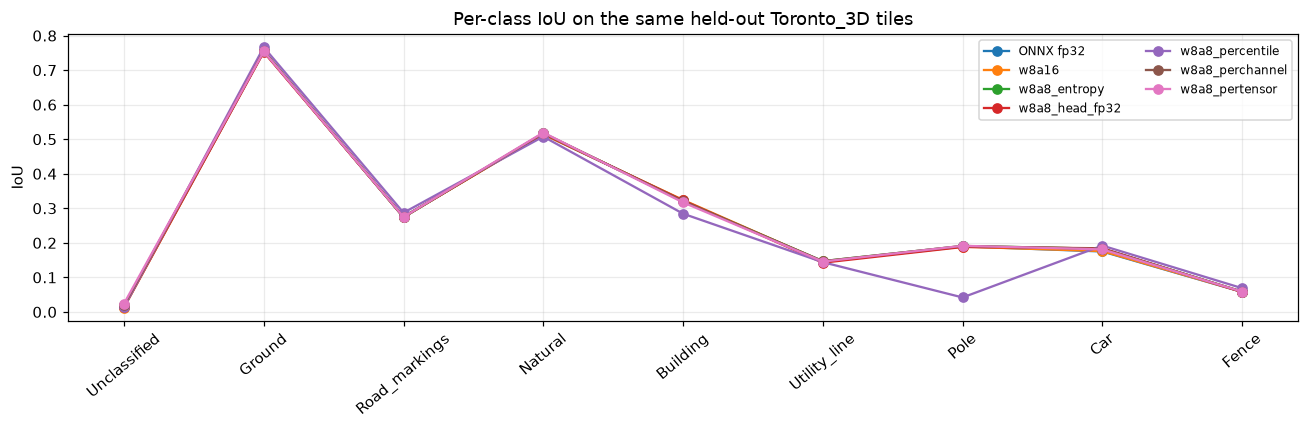

In [14]:
rows = []
if fp32_row is not None:
    rows.append(fp32_row)
for result in quant_results:
    rows.append({key: result[key] for key in ("model", "OA", "mIoU", "tiles_per_sec", "p50_ms", "p99_ms", "size_kb")})

if rows:
    import pandas as pd
    comparison = pd.DataFrame(rows).set_index("model")
    display(comparison.style.format({
        "OA": "{:.4f}", "mIoU": "{:.4f}", "tiles_per_sec": "{:.2f}",
        "p50_ms": "{:.2f}", "p99_ms": "{:.2f}", "size_kb": "{:.1f}",
    }, na_rep="—"))

    metric_rows = ([{"model": "ONNX fp32", "metrics": fp32_metrics, "predictions": fp32_pred,
                     "confusion": confusion_from_predictions(fp32_pred, eval_targets)}]
                   if fp32_row is not None else []) + quant_results
    fig, ax = plt.subplots(figsize=(12, 4))
    for item in metric_rows:
        current_iou = item["metrics"]["IoU"] if "metrics" in item else summarize_confusion(item["confusion"])["IoU"]
        ax.plot(CLASS_NAMES, current_iou, marker="o", label=item["model"])
    ax.set_ylabel("IoU")
    ax.set_title("Per-class IoU on the same held-out Toronto_3D tiles")
    ax.tick_params(axis="x", rotation=40)
    ax.legend(ncol=2, fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print("No quantized models found. Export FP32 ONNX and run the PTQ command in the introduction.")

## 8. Inspect quantization details

ONNX QDQ represents quantization explicitly: `QuantizeLinear` maps float tensors to integer values using scale and zero-point initializers; `DequantizeLinear` converts back where required by the graph. Weight quantization may use per-output-channel scales, while activation calibration is typically per-tensor.

In [15]:
def initializer_array(graph, name):
    for initializer in graph.initializer:
        if initializer.name == name:
            return onnx.numpy_helper.to_array(initializer)
    return None


def describe_qdq(path):
    graph = onnx.load(str(path)).graph
    nodes = [node for node in graph.node if node.op_type in {"QuantizeLinear", "DequantizeLinear"}]
    print(f"{path.name}: {len(nodes)} Q/DQ nodes")
    for node in nodes[:12]:
        scale = initializer_array(graph, node.input[1]) if len(node.input) > 1 else None
        zero = initializer_array(graph, node.input[2]) if len(node.input) > 2 else None
        scale_info = "dynamic" if scale is None else f"shape={scale.shape}, range=[{scale.min():.3g}, {scale.max():.3g}]"
        zero_info = "default" if zero is None else f"shape={zero.shape}, dtype={zero.dtype}, values={np.asarray(zero).reshape(-1)[:4]}"
        axis = next((attr.i for attr in node.attribute if attr.name == "axis"), None)
        print(f"  {node.op_type:17s} tensor={node.input[0]:30s} {scale_info}; zero={zero_info}; axis={axis}")

if FP32_ONNX.is_file():
    fp_ops = Counter(node.op_type for node in onnx.load(str(FP32_ONNX)).graph.node)
    print("FP32 ops:", fp_ops)
    print("BatchNormalization nodes after export:", fp_ops.get("BatchNormalization", 0))
for path in quant_paths[:3]:
    describe_qdq(path)

# Hand-computed affine quantization: asymmetric 8-bit encoding includes a zero-point.
def qparams(xmin, xmax, bits=8):
    xmin, xmax = min(float(xmin), 0.0), max(float(xmax), 0.0)
    qmin, qmax = 0, 2**bits - 1
    scale = (xmax - xmin) / (qmax - qmin)
    zero_point = int(np.clip(np.round(qmin - xmin / scale), qmin, qmax))
    return scale, zero_point

example = np.array([-0.4, 0.0, 0.2, 1.0], dtype=np.float32)
scale, zero = qparams(example.min(), example.max())
q = np.clip(np.round(example / scale) + zero, 0, 255).astype(np.uint8)
reconstructed = scale * (q.astype(np.float32) - zero)
print(f"example: scale={scale:.5f}, zero_point={zero}, q={q.tolist()}, max_abs_error={np.max(np.abs(example-reconstructed)):.5f}")

FP32 ops: Counter({'Conv': 7, 'Relu': 6, 'ReduceMax': 1, 'Expand': 1, 'Concat': 1})
BatchNormalization nodes after export: 0
pointnet_toronto_w8a16.onnx: 34 Q/DQ nodes
  DequantizeLinear  tensor=glob.0.0.weight_bias_quantized shape=(128,), range=[1.89e-07, 4.99e-07]; zero=shape=(128,), dtype=int32, values=[0 0 0 0]; axis=0
  DequantizeLinear  tensor=glob.0.0.weight_quantized      shape=(128,), range=[0.00162, 0.00429]; zero=shape=(128,), dtype=int8, values=[0 0 0 0]; axis=0
  DequantizeLinear  tensor=glob.1.0.weight_bias_quantized shape=(256,), range=[1.63e-07, 3.94e-07]; zero=shape=(256,), dtype=int32, values=[0 0 0 0]; axis=0
  DequantizeLinear  tensor=glob.1.0.weight_quantized      shape=(256,), range=[0.0012, 0.00291]; zero=shape=(256,), dtype=int8, values=[0 0 0 0]; axis=0
  DequantizeLinear  tensor=head.0.0.weight_bias_quantized shape=(256,), range=[1.05e-07, 3.18e-07]; zero=shape=(256,), dtype=int32, values=[0 0 0 0]; axis=0
  DequantizeLinear  tensor=head.0.0.weight_quantized  

### What to investigate

- Does per-channel W8A8 retain mIoU better than per-tensor calibration?
- Which classes lose the most IoU? Inspect the confusion matrix to see which labels they collapse into.
- Does a percentile or entropy calibration variant help when activation outliers dominate?
- How does measured CPU latency compare with file-size reduction? Quantized weights can shrink substantially even if this CPU does not have a faster integer kernel.
- Try additional calibration scans, keeping L004 held out, and record whether calibration coverage improves rare-class behavior.